# 01. Data Understanding

# Load Dataset and Check Dimensions

In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")

data_path = "data/Dataset/Parquet/Combined Data/Combined_dataset.parquet"
out_dir = "data/GeneratedOutput/01.EDA"
if not os.path.exists(data_path):
    data_path = os.path.join("..", "..", data_path)
    out_dir = os.path.join("..", "..", out_dir)
os.makedirs(out_dir, exist_ok=True)

df = pd.read_parquet(data_path)
print(f"Rows: {len(df):,}")
print(f"Columns: {len(df.columns)}")
df.head()

Rows: 4,297,895
Columns: 14


,Country,Area,Waterbody Type,Date,Ammonia (mg/l),Biochemical Oxygen Demand (mg/l),Dissolved Oxygen (mg/l),Orthophosphate (mg/l),pH (ph units),Temperature (cel),Nitrogen (mg/l),Nitrate (mg/l),CCME_Values,CCME_WQI
0,Australia,Torrens River Adelaide Zoo Pedestrian Bridge,River,01-12-2014,0.083,NaN,4.15,0.062,NaN,24.7,0.81,0.769,93.102127,Good
1,Australia,Torrens River Adelaide Zoo Pedestrian Bridge,River,02-02-2015,0.010,NaN,12.07,0.006,NaN,22.4,1.21,0.682,100.000000,Excellent
2,Australia,Torrens River Adelaide Zoo Pedestrian Bridge,River,02-03-2015,0.013,NaN,10.59,0.026,NaN,17.0,0.94,0.140,100.000000,Excellent
3,Australia,Torrens River Adelaide Zoo Pedestrian Bridge,River,13-04-2015,0.056,NaN,3.42,0.026,7.4,17.0,0.56,1.030,100.000000,Excellent
4,Australia,Torrens River Adelaide Zoo Pedestrian Bridge,River,15-01-2015,0.086,NaN,3.91,0.075,7.4,23.2,0.76,0.428,92.814413,Good


# Dataset Schema and Data Types

In [2]:
schema_df = pd.DataFrame({
    "Column": df.columns,
    "Dtype": df.dtypes.astype(str),
    "Non-Null Count": df.notnull().sum(),
    "Null %": (df.isnull().sum() / len(df) * 100).round(2)
}).reset_index(drop=True)
schema_df

,Column,Dtype,Non-Null Count,Null %
0,Country,str,4297895,0.00
1,Area,str,4297895,0.00
2,Waterbody Type,str,4297895,0.00
3,Date,str,4297895,0.00
4,Ammonia (mg/l),float64,2828064,34.20
5,Biochemical Oxygen Demand (mg/l),float64,2831561,34.12
6,Dissolved Oxygen (mg/l),float64,3156915,26.55
7,Orthophosphate (mg/l),float64,2828064,34.20
8,pH (ph units),float64,3096820,27.95
9,Temperature (cel),float64,4291337,0.15


# Country Distribution

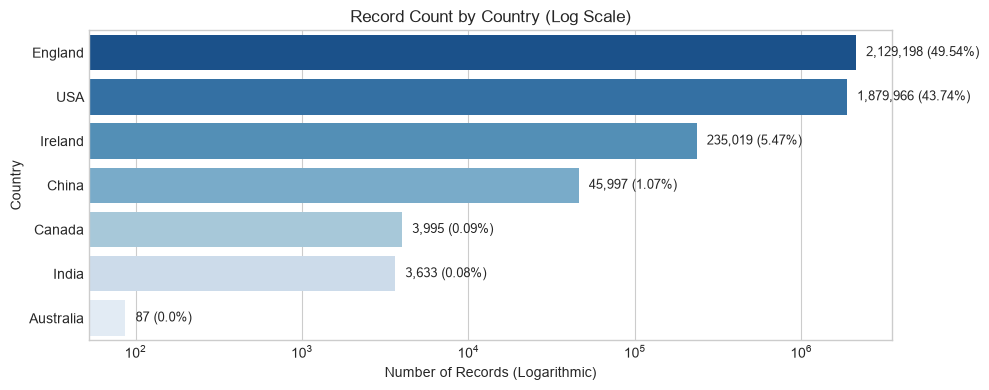

,Records,Share (%)
Country,,
England,2129198,49.54
USA,1879966,43.74
Ireland,235019,5.47
China,45997,1.07
Canada,3995,0.09
India,3633,0.08
Australia,87,0.00


In [3]:
country_counts = df["Country"].value_counts()
country_pcts = (country_counts / len(df) * 100).round(2)

fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(x=country_counts.values, y=country_counts.index, palette="Blues_r", hue=country_counts.index, legend=False, ax=ax)
ax.set_xscale("log")
ax.set_title("Record Count by Country (Log Scale)")
ax.set_xlabel("Number of Records (Logarithmic)")
for i, count in enumerate(country_counts.values):
    ax.text(count * 1.15, i, f"{count:,} ({country_pcts.iloc[i]}%)", va="center", fontsize=9)
plt.tight_layout()
plt.show()

pd.DataFrame({"Records": country_counts, "Share (%)": country_pcts})

# Waterbody Types and Monitoring Stations

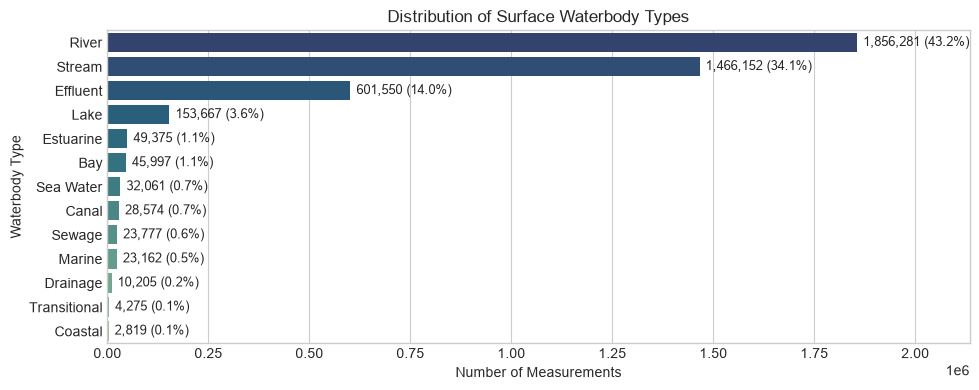

Total Unique Monitoring Stations: 64,665


In [4]:
wb_counts = df["Waterbody Type"].value_counts()

fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(x=wb_counts.values, y=wb_counts.index, palette="crest_r", hue=wb_counts.index, legend=False, ax=ax)
ax.set_title("Distribution of Surface Waterbody Types")
ax.set_xlabel("Number of Measurements")
for i, count in enumerate(wb_counts.values):
    ax.text(count + 15000, i, f"{count:,} ({(count/len(df)*100):.1f}%)", va="center", fontsize=9)
plt.xlim(0, wb_counts.max() * 1.15)
plt.tight_layout()
plt.show()

print(f"Total Unique Monitoring Stations: {df['Area'].nunique():,}")

# Temporal Range of Observations

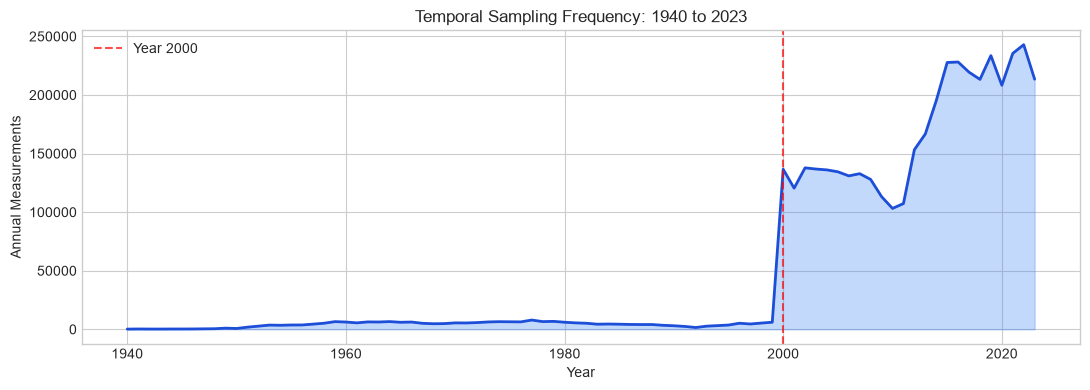

In [5]:
df["Year"] = pd.to_datetime(df["Date"], format="%d-%m-%Y", errors="coerce").dt.year
year_counts = df["Year"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(11, 4))
ax.fill_between(year_counts.index, year_counts.values, color="#3b82f6", alpha=0.3)
ax.plot(year_counts.index, year_counts.values, color="#1d4ed8", lw=2)
ax.set_title("Temporal Sampling Frequency: 1940 to 2023")
ax.set_xlabel("Year")
ax.set_ylabel("Annual Measurements")
ax.axvline(2000, color="red", linestyle="--", alpha=0.7, label="Year 2000")
ax.legend()
plt.tight_layout()
plt.show()

summary_profile = pd.DataFrame({
    "Metric": ["Total Rows", "Total Columns", "Total Unique Stations", "Date Start", "Date End", "Top Country", "Top Waterbody"],
    "Value": [
        f"{len(df):,}",
        f"{len(df.columns)}",
        f"{df['Area'].nunique():,}",
        str(df["Date"].min()),
        str(df["Date"].max()),
        f"{df['Country'].value_counts().index[0]} ({df['Country'].value_counts().iloc[0]:,})",
        f"{df['Waterbody Type'].value_counts().index[0]} ({df['Waterbody Type'].value_counts().iloc[0]:,})"
    ]
})
summary_profile.to_parquet(os.path.join(out_dir, "01_dataset_summary_profile.parquet"), index=False, compression="snappy")

# Sensor Missingness Rates

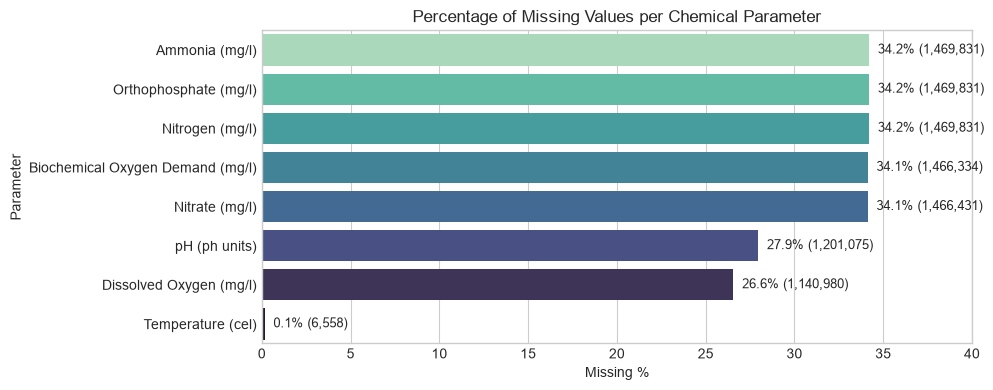

,Parameter,Missing Count,Missing %,Present Count
0,Ammonia (mg/l),1469831,34.20,2828064
1,Orthophosphate (mg/l),1469831,34.20,2828064
2,Nitrogen (mg/l),1469831,34.20,2828064
3,Biochemical Oxygen Demand (mg/l),1466334,34.12,2831561
4,Nitrate (mg/l),1466431,34.12,2831464
5,pH (ph units),1201075,27.95,3096820
6,Dissolved Oxygen (mg/l),1140980,26.55,3156915
7,Temperature (cel),6558,0.15,4291337


In [6]:
chemical_cols = [
    "Ammonia (mg/l)", "Biochemical Oxygen Demand (mg/l)",
    "Dissolved Oxygen (mg/l)", "Orthophosphate (mg/l)",
    "pH (ph units)", "Temperature (cel)", "Nitrogen (mg/l)", "Nitrate (mg/l)"
]

null_counts = df[chemical_cols].isnull().sum()
null_pcts = (null_counts / len(df) * 100).round(2)

missing_df = pd.DataFrame({
    "Parameter": chemical_cols,
    "Missing Count": null_counts.values,
    "Missing %": null_pcts.values,
    "Present Count": (len(df) - null_counts).values
}).sort_values("Missing %", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(data=missing_df, x="Missing %", y="Parameter", palette="mako_r", hue="Parameter", legend=False, ax=ax)
ax.set_title("Percentage of Missing Values per Chemical Parameter")
ax.set_xlim(0, 40)
for i, pct in enumerate(missing_df["Missing %"]):
    ax.text(pct + 0.5, i, f"{pct:.1f}% ({missing_df['Missing Count'].iloc[i]:,})", va="center", fontsize=9)
plt.tight_layout()
plt.show()

missing_df

# Missingness Patterns Across Countries

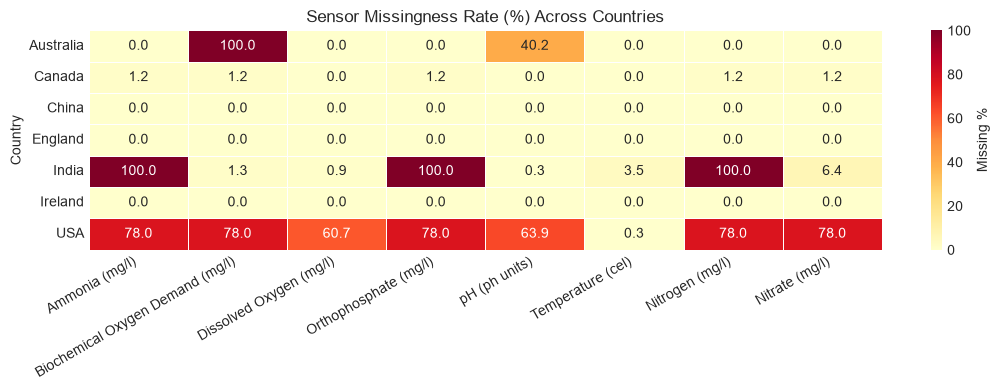

In [7]:
country_missing = df.groupby("Country")[chemical_cols].apply(lambda g: (g.isnull().mean() * 100).round(1))

fig, ax = plt.subplots(figsize=(11, 4))
sns.heatmap(country_missing, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={"label": "Missing %"}, linewidths=0.5, ax=ax)
ax.set_title("Sensor Missingness Rate (%) Across Countries")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

country_missing.reset_index().to_parquet(os.path.join(out_dir, "02_missingness_patterns.parquet"), index=False, compression="snappy")

# Sensor Co-Occurrence and Complete Cases

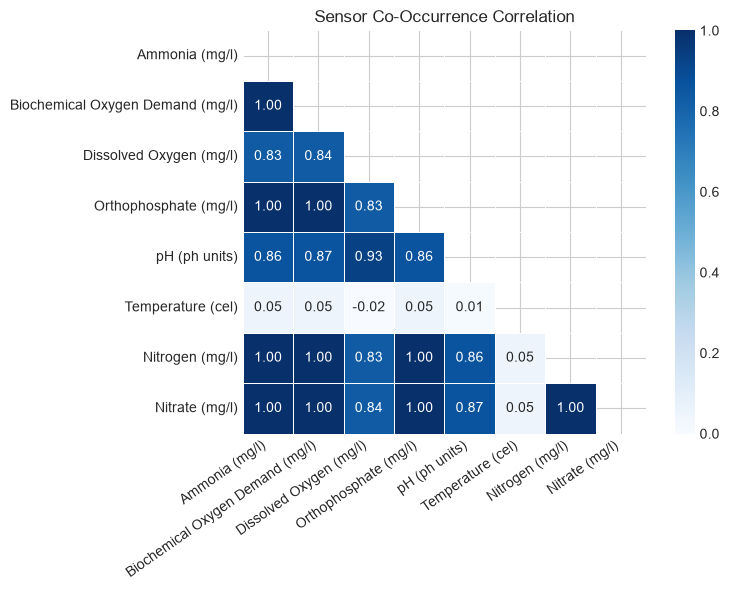

Complete-Case Records (All 8 Sensors Active): 2,827,977 (65.80%)


In [8]:
presence_matrix = df[chemical_cols].notnull().astype(int)
co_occurrence = presence_matrix.corr()

fig, ax = plt.subplots(figsize=(8, 6))
mask = np.triu(np.ones_like(co_occurrence, dtype=bool))
sns.heatmap(co_occurrence, mask=mask, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, square=True, linewidths=0.5, ax=ax)
ax.set_title("Sensor Co-Occurrence Correlation")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

complete_count = df[chemical_cols].notnull().all(axis=1).sum()
print(f"Complete-Case Records (All 8 Sensors Active): {complete_count:,} ({complete_count/len(df)*100:.2f}%)")

# Numerical Summary Statistics

In [9]:
df[chemical_cols].describe().round(3)

,Ammonia (mg/l),Biochemical Oxygen Demand (mg/l),Dissolved Oxygen (mg/l),Orthophosphate (mg/l),pH (ph units),Temperature (cel),Nitrogen (mg/l),Nitrate (mg/l)
count,2828064.000,2831561.000,3156915.000,2828064.000,3096820.000,4291337.000,2828064.000,2831464.000
mean,1.171,4.887,9.470,0.710,6.829,-4.881,5.209,4.764
std,5.669,16.423,562.828,2.089,985.401,4317.683,6.200,6.093
min,-0.005,-2.000,-999999.000,-0.004,-999999.000,-999999.000,0.000,0.000
25%,0.030,1.600,9.390,0.040,7.510,9.300,0.780,1.170
50%,0.055,2.700,10.200,0.107,7.780,11.900,4.000,4.500
75%,0.317,2.830,10.900,0.227,8.000,17.200,6.320,4.940
max,200.000,534.500,23.750,100.000,67115.000,98.000,46.000,790.020
